In [1]:
import os, sys
import pandas as pd, numpy as np

root = os.getcwd()
while not os.path.exists(os.path.join(root, "src", "db.py")):
    parent = os.path.dirname(root)
    if parent == root:
        raise FileNotFoundError("src/db.py not found")
    root = parent

for m in [k for k in sys.modules if k == "src" or k.startswith("src.")]:
    del sys.modules[m]            # forget any wrong 'src' already loaded
sys.path.insert(0, root)          # put the project folder FIRST

import src
print("src loaded from:", list(src.__path__))
from src.db import get_engine
engine = get_engine()
print("engine ready")

src loaded from: ['c:\\Users\\shash\\Desktop\\churn_clv_system\\src']
engine ready


In [2]:
import pandas as pd
import numpy as np

df_raw = pd.read_sql("SELECT * FROM customers", engine)
df = df_raw.copy()
df.shape

(7043, 33)

### Basic Checks

In [3]:
df

,customer_id,count,country,state,city,zip_code,lat_long,latitude,longitude,gender,...,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn_label,churn_value,churn_score,cltv,churn_reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,None
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,None
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,None
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,None


In [4]:
pd.set_option('display.max_columns', None)

df.isnull().sum()

customer_id             0
count                   0
country                 0
state                   0
city                    0
zip_code                0
lat_long                0
latitude                0
longitude               0
gender                  0
senior_citizen          0
partner                 0
dependents              0
tenure_months           0
phone_service           0
multiple_lines          0
internet_service        0
online_security         0
online_backup           0
device_protection       0
tech_support            0
streaming_tv            0
streaming_movies        0
contract                0
paperless_billing       0
payment_method          0
monthly_charges         0
total_charges           0
churn_label             0
churn_value             0
churn_score             0
cltv                    0
churn_reason         5174
dtype: int64

In [5]:
df.describe()

,count,latitude,longitude,tenure_months,monthly_charges,churn_value,churn_score,cltv
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   object 
 1   count              7043 non-null   int64  
 2   country            7043 non-null   object 
 3   state              7043 non-null   object 
 4   city               7043 non-null   object 
 5   zip_code           7043 non-null   object 
 6   lat_long           7043 non-null   object 
 7   latitude           7043 non-null   float64
 8   longitude          7043 non-null   float64
 9   gender             7043 non-null   object 
 10  senior_citizen     7043 non-null   object 
 11  partner            7043 non-null   object 
 12  dependents         7043 non-null   object 
 13  tenure_months      7043 non-null   int64  
 14  phone_service      7043 non-null   object 
 15  multiple_lines     7043 non-null   object 
 16  internet_service   7043 

### EDA

In [7]:
# total_charges: text -> number; the 11 blanks are tenure=0 customers, never billed
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce").fillna(0)

# "No phone service" / "No internet service" repeat what another column already says
df["multiple_lines"] = df["multiple_lines"].replace({"No phone service": "No"})
addons = ["online_security", "online_backup", "device_protection",
          "tech_support", "streaming_tv", "streaming_movies"]
df[addons] = df[addons].replace({"No internet service": "No"})

In [8]:
df["multiple_lines"]
#type("multiple_lines")

0        No
1        No
2       Yes
3       Yes
4       Yes
       ... 
7038     No
7039    Yes
7040    Yes
7041     No
7042     No
Name: multiple_lines, Length: 7043, dtype: object

In [9]:
df["total_charges"].isna().sum(), df["multiple_lines"].unique(), df["tech_support"].unique()

(np.int64(0),
 array(['No', 'Yes'], dtype=object),
 array(['No', 'Yes'], dtype=object))

In [10]:
df["n_services"] = (df[addons] == "Yes").sum(axis=1)
df["has_autopay"] = df["payment_method"].str.contains("automatic").astype(int)

In [11]:
features = [
    "gender", "senior_citizen", "partner", "dependents", "tenure_months",
    "phone_service", "multiple_lines", "internet_service", "online_security",
    "online_backup", "device_protection", "tech_support", "streaming_tv",
    "streaming_movies", "contract", "paperless_billing", "payment_method",
    "monthly_charges", "total_charges",
    "n_services", "has_autopay",
]
target = "churn_value"

model_df = df[features + [target]].copy()

In [12]:
leaks = ["churn_reason", "churn_label", "churn_score", "cltv", "customer_id"]
assert not set(leaks) & set(model_df.columns), "leaky column present"
print(model_df.shape)              # (7043, 22)
print(model_df.isna().sum().sum()) # 0

(7043, 22)
0


In [13]:
model_df.to_sql("customers_model", engine, if_exists="replace", index=False)

43

In [14]:
df2 = pd.read_sql("customers_model",engine)
df2.shape
df2

,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,n_services,has_autopay,churn_value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,2,0,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,3,0,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,4,0,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,4,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Female,No,No,No,72,Yes,No,No,No,No,No,No,No,No,Two year,Yes,Bank transfer (automatic),21.15,1419.40,0,1,0
7039,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,5,0,0
7040,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,4,1,0
7041,Female,No,Yes,Yes,11,No,No,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,1,0,0


In [15]:
model_df["internet_service"]

0               DSL
1       Fiber optic
2       Fiber optic
3       Fiber optic
4       Fiber optic
           ...     
7038             No
7039            DSL
7040    Fiber optic
7041            DSL
7042    Fiber optic
Name: internet_service, Length: 7043, dtype: object

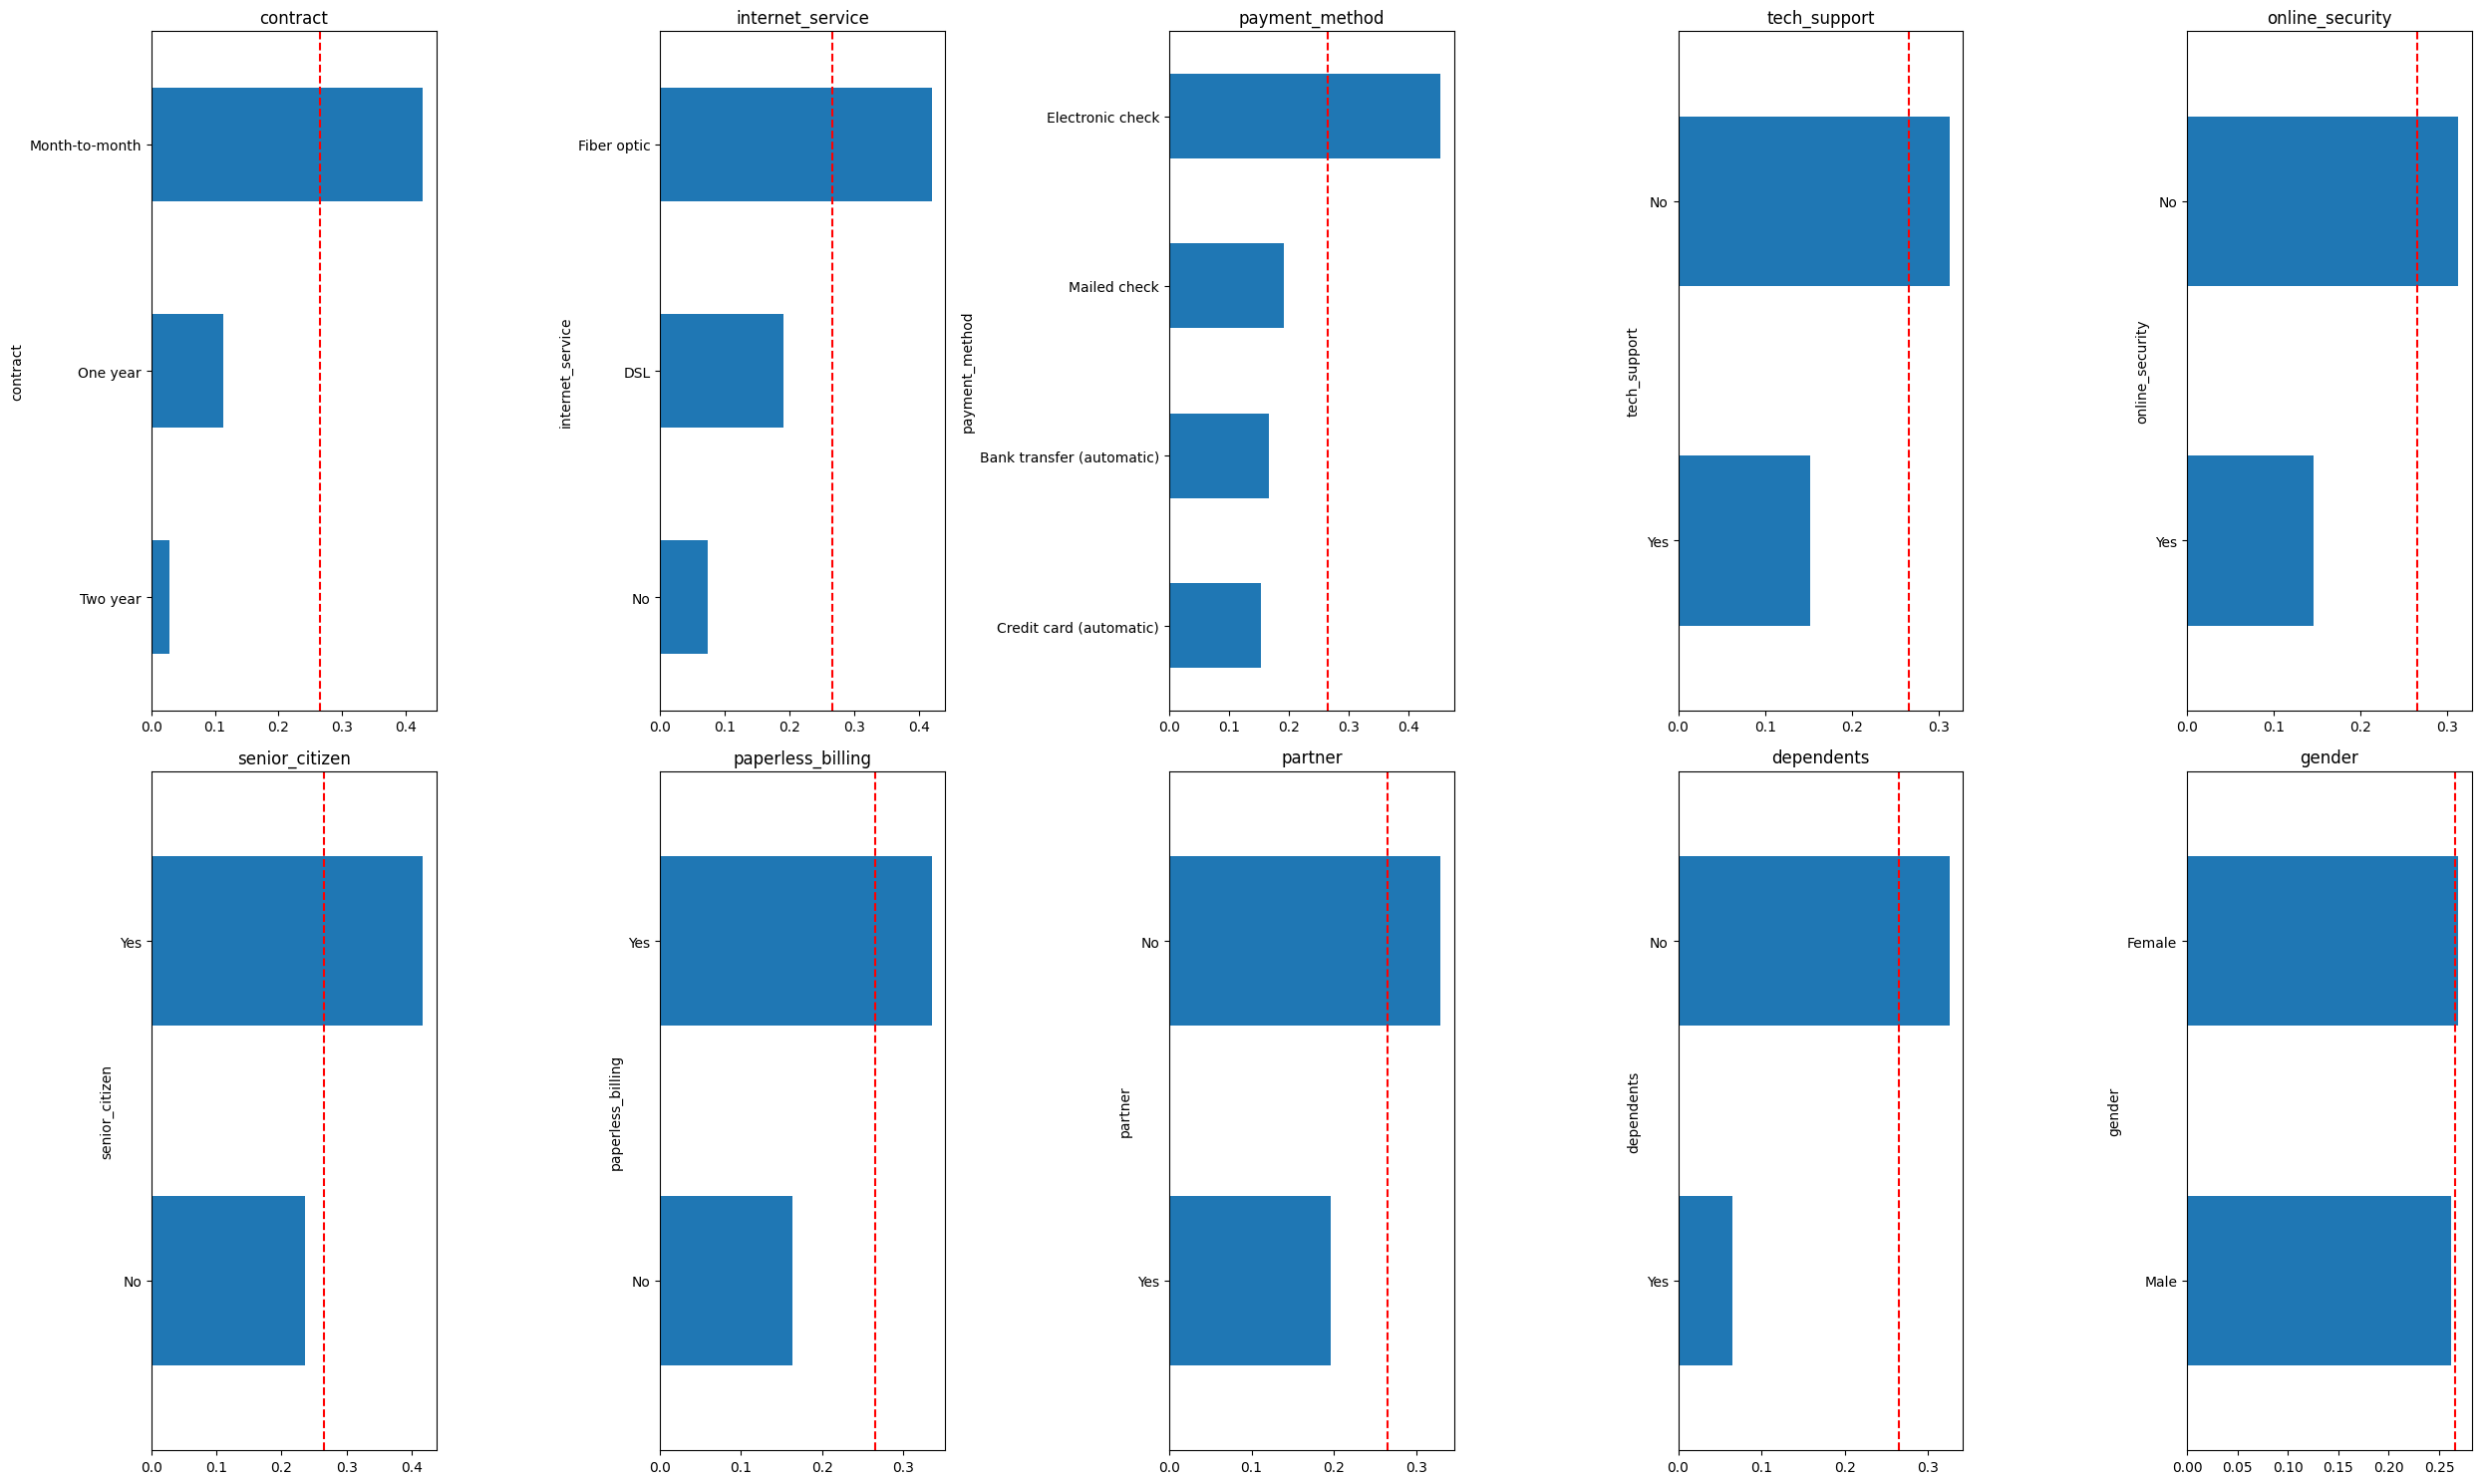

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

cat_cols = ["contract", "internet_service", "payment_method", "tech_support",
            "online_security", "senior_citizen", "paperless_billing",
            "partner", "dependents", "gender"]

fig, axes = plt.subplots(2, 5, figsize=(25, 15))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = model_df.groupby(col)["churn_value"].mean().sort_values()
    rate.plot.barh(ax=ax)
    ax.axvline(model_df["churn_value"].mean(), color="red", linestyle="--")
    ax.set_title(col)
plt.tight_layout()
plt.show()

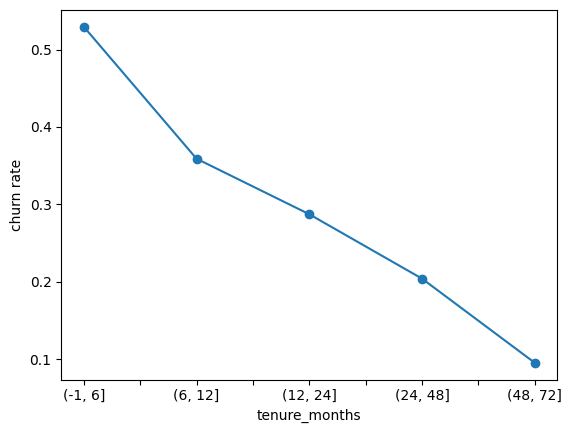

In [17]:
tenure_bin = pd.cut(model_df["tenure_months"], bins=[-1, 6, 12, 24, 48, 72])
model_df.groupby(tenure_bin, observed=True)["churn_value"].mean().plot(marker="o")
plt.ylabel("churn rate")
plt.show()

In [18]:
rows = []
for col in cat_cols:
    g = model_df.groupby(col)["churn_value"].agg(["mean", "count"])
    rows.append({
        "feature": col,
        "spread": g["mean"].max() - g["mean"].min(),
        "smallest_group": g["count"].min(),
    })
pd.DataFrame(rows).sort_values("spread", ascending=False)




,feature,spread,smallest_group
0,contract,0.398778,1473
1,internet_service,0.344878,1526
2,payment_method,0.300423,1522
8,dependents,0.260366,1627
5,senior_citizen,0.180751,1142
6,paperless_billing,0.172350,2872
4,online_security,0.167184,2019
3,tech_support,0.160199,2044
7,partner,0.132931,3402
9,gender,0.007605,3488


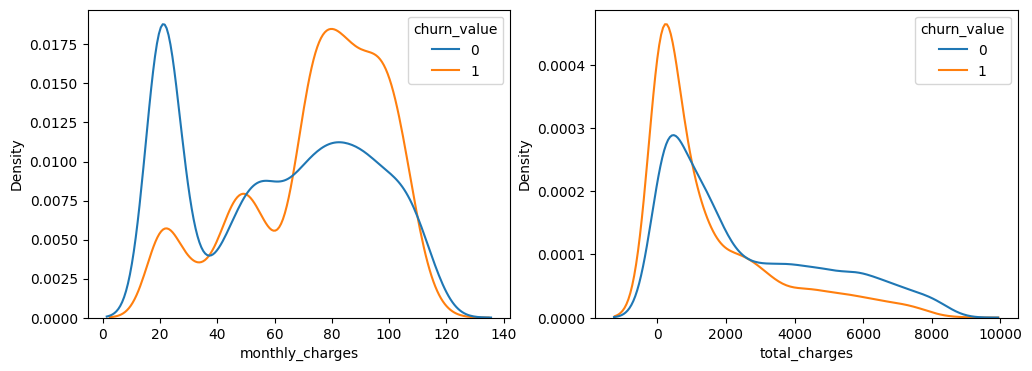

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["monthly_charges", "total_charges"]):
    sns.kdeplot(data=model_df, x=col, hue="churn_value", common_norm=False, ax=ax)
plt.show()

In [20]:
model_df.groupby("internet_service")["monthly_charges"].mean()

internet_service
DSL            58.102169
Fiber optic    91.500129
No             21.079194
Name: monthly_charges, dtype: float64

In [21]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns="churn_value")
y = model_df["churn_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

X_train.shape, X_test.shape, y_train.mean(), y_test.mean()

((5634, 21),
 (1409, 21),
 np.float64(0.2653532126375577),
 np.float64(0.2654364797728886))

In [22]:
yes_no = ["senior_citizen", "partner", "dependents", "phone_service",
          "multiple_lines", "online_security", "online_backup",
          "device_protection", "tech_support", "streaming_tv",
          "streaming_movies", "paperless_billing"]

def encode(X):
    X = X.copy()
    X[yes_no] = (X[yes_no] == "Yes").astype(int)
    X["gender"] = (X["gender"] == "Male").astype(int)
    X["contract"] = X["contract"].map(
        {"Month-to-month": 0, "One year": 1, "Two year": 2})
    return pd.get_dummies(X, columns=["internet_service", "payment_method"], dtype=int)

X_train_enc = encode(X_train)
X_test_enc = encode(X_test).reindex(columns=X_train_enc.columns, fill_value=0)

In [23]:
X_train_enc.select_dtypes("object").columns
X_train_enc.isna().sum().sum()
X_train_enc.shape, X_test_enc.shape

((5634, 26), (1409, 26))

In [24]:
X_train_enc.select_dtypes("object").columns     # empty
X_train_enc.isna().sum().sum()                  # 0
X_train_enc.shape, X_test_enc.shape
list(X_train_enc.columns) == list(X_test_enc.columns)   # True

True

In [25]:
list(X_train_enc.columns)

['gender',
 'senior_citizen',
 'partner',
 'dependents',
 'tenure_months',
 'phone_service',
 'multiple_lines',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies',
 'contract',
 'paperless_billing',
 'monthly_charges',
 'total_charges',
 'n_services',
 'has_autopay',
 'internet_service_DSL',
 'internet_service_Fiber optic',
 'internet_service_No',
 'payment_method_Bank transfer (automatic)',
 'payment_method_Credit card (automatic)',
 'payment_method_Electronic check',
 'payment_method_Mailed check']

In [26]:
X_train_enc.select_dtypes("object").columns   # should be empty


Index([], dtype='object')

In [27]:

X_train_enc.isna().sum().sum()                # should be 0

np.int64(0)

In [28]:
X_train_enc                # should be (5634, 20), (1409, 20)

,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,monthly_charges,total_charges,n_services,has_autopay,internet_service_DSL,internet_service_Fiber optic,internet_service_No,payment_method_Bank transfer (automatic),payment_method_Credit card (automatic),payment_method_Electronic check,payment_method_Mailed check
4626,0,0,1,0,2,1,0,0,0,0,0,1,0,0,1,84.05,134.05,1,0,0,1,0,0,0,1,0
4192,0,0,0,0,8,1,0,0,0,1,1,0,1,0,0,64.10,504.05,3,0,1,0,0,0,0,0,1
5457,1,0,1,1,57,1,0,1,1,0,1,0,0,1,0,59.60,3509.40,3,0,1,0,0,0,0,0,1
4717,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,24.00,24.00,0,0,0,0,1,0,0,0,1
4673,0,0,1,1,3,1,0,0,0,0,0,0,0,0,0,19.30,54.70,0,0,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6507,0,0,1,0,71,1,1,0,1,1,1,1,1,2,0,109.25,7707.70,5,0,0,1,0,0,0,1,0
1652,1,0,0,0,2,1,0,0,0,0,0,0,0,0,0,46.05,80.35,0,1,1,0,0,1,0,0,0
1227,0,1,0,0,25,1,1,1,1,0,0,1,1,0,1,102.80,2660.20,4,0,0,1,0,0,0,0,1
3870,1,0,0,0,2,1,0,0,0,0,0,0,0,0,0,19.85,51.60,0,0,0,0,1,0,0,0,1


In [29]:
model_df.shape

(7043, 22)

In [30]:
X_test_enc.head().shape

(5, 26)

In [31]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

dummy = DummyClassifier(strategy="prior").fit(X_train_enc, y_train)
p = dummy.predict_proba(X_test_enc)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, p))
print("PR-AUC :", average_precision_score(y_test, p))

ROC-AUC: 0.5
PR-AUC : 0.2654364797728886


In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logit.fit(X_train_enc, y_train)
proba = logit.predict_proba(X_test_enc)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, proba))
print("PR-AUC :", average_precision_score(y_test, proba))

ROC-AUC: 0.877050556718076
PR-AUC : 0.7577043861073265


In [33]:
coefs = pd.Series(logit[-1].coef_[0], index=X_train_enc.columns).sort_values()
coefs

monthly_charges                            -5.822182
internet_service_No                        -2.552641
tenure_months                              -1.243824
contract                                   -0.833353
dependents                                 -0.667014
internet_service_DSL                       -0.363245
has_autopay                                -0.055131
payment_method_Credit card (automatic)     -0.044023
payment_method_Mailed check                -0.023759
payment_method_Bank transfer (automatic)   -0.022401
gender                                     -0.007249
senior_citizen                              0.009246
payment_method_Electronic check             0.078873
tech_support                                0.109479
online_security                             0.112275
partner                                     0.141267
paperless_billing                           0.141641
online_backup                               0.209342
device_protection                           0.

In [34]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split

# carve a validation set out of TRAIN, so early stopping never touches the test set
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_enc, y_train, test_size=0.2, stratify=y_train, random_state=42)

gbm = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.03, num_leaves=15,
    min_child_samples=30, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, verbose=-1)

gbm.fit(X_tr, y_tr,
        eval_set=[(X_val, y_val)], eval_metric="auc",
        callbacks=[lgb.early_stopping(50, verbose=False)])

print("trees used:", gbm.best_iteration_)
p = gbm.predict_proba(X_test_enc)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, p))
print("PR-AUC :", average_precision_score(y_test, p))

c:\Users\shash\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\shash\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\shash\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\shash\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1038

trees used: 143
ROC-AUC: 0.8899545325376527
PR-AUC : 0.7753541938041836


In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gbm_cv = lgb.LGBMClassifier(
    n_estimators=150, learning_rate=0.03, num_leaves=15, min_child_samples=30,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, verbose=-1)

for name, m in [("logistic", logit), ("lightgbm", gbm_cv)]:
    s = cross_val_score(m, X_train_enc, y_train, cv=cv, scoring="roc_auc")
    print(name, round(s.mean(), 3), "+/-", round(s.std(), 3))

logistic 0.884 +/- 0.013
lightgbm 0.889 +/- 0.007


In [45]:
pip install shap

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 2.3 MB/s  0:00:00
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [slicer]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
import shap;

explainer = shap.TreeExplainer(gbm)
sv = explainer(X_test_enc)
if sv.values.ndim == 3:        # some versions return one set of values per class
    sv = sv[:, :, 1]           # keep the "churn" class

c:\Users\shash\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


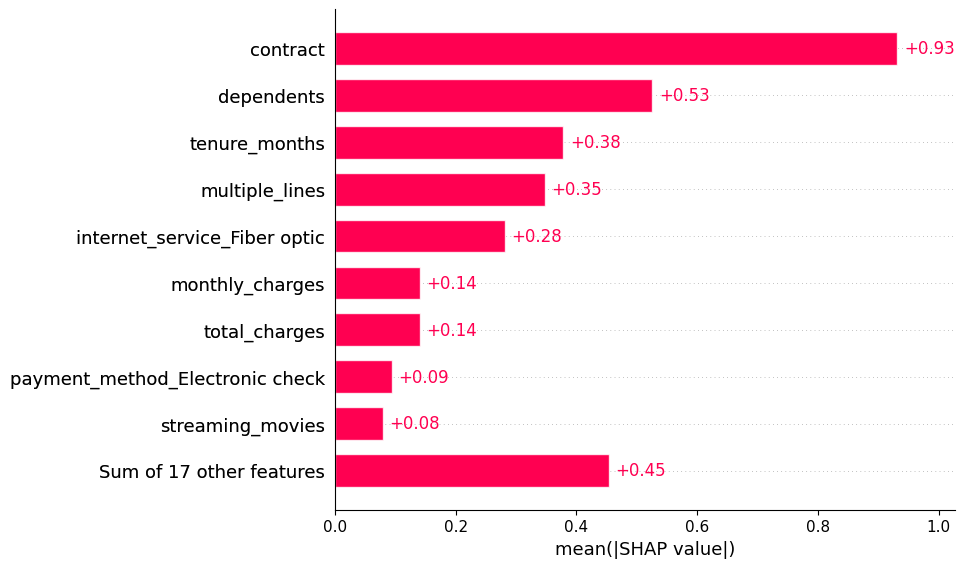

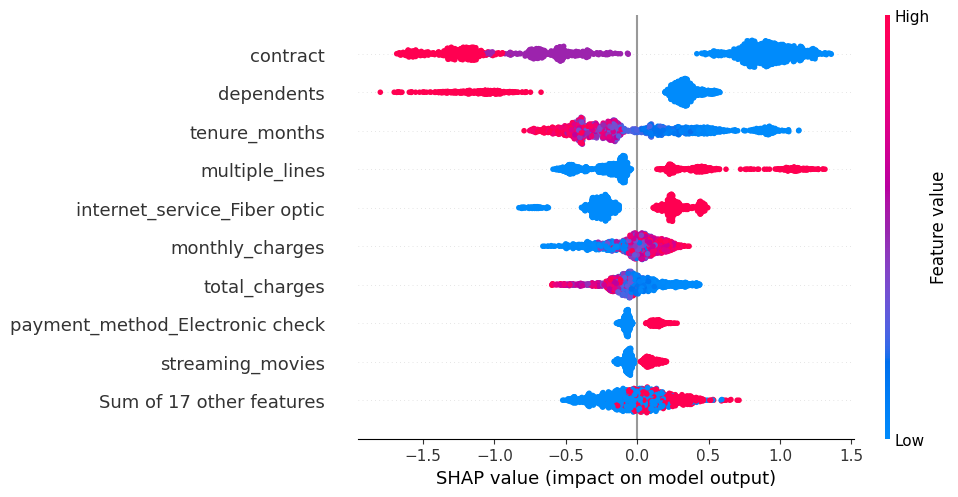

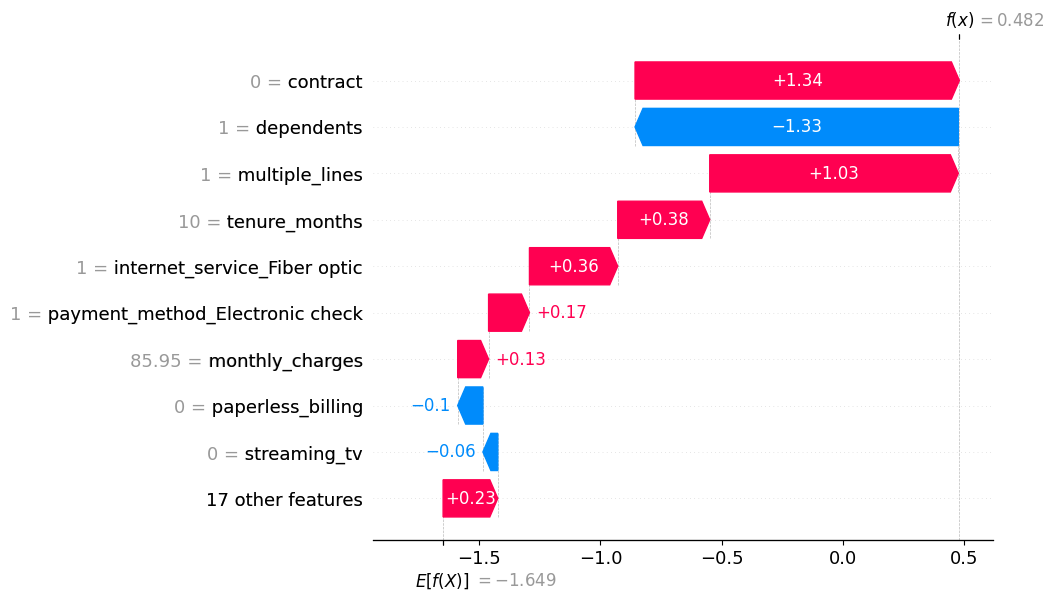

In [35]:
shap.plots.bar(sv)                  # which features matter most overall?
shap.plots.beeswarm(sv)             # in which direction does each feature push?
shap.plots.waterfall(sv[0])         # why was THIS customer scored this way?

In [36]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(gbm, "models/churn_lgbm.pkl")

X_all_enc = encode(X).reindex(columns=X_train_enc.columns, fill_value=0)
scores = pd.DataFrame({
    "customer_id": df["customer_id"],
    "churn_prob": gbm.predict_proba(X_all_enc)[:, 1],
})
scores.head()

,customer_id,churn_prob
0,3668-QPYBK,0.366592
1,9237-HQITU,0.439615
2,9305-CDSKC,0.810162
3,7892-POOKP,0.445530
4,0280-XJGEX,0.319699


In [37]:
scores.head()

,customer_id,churn_prob
0,3668-QPYBK,0.366592
1,9237-HQITU,0.439615
2,9305-CDSKC,0.810162
3,7892-POOKP,0.445530
4,0280-XJGEX,0.319699


In [38]:
import joblib
joblib.dump(gbm, "../models/churn_lgbm.pkl")
joblib.dump(list(X_train_enc.columns), "../models/encoded_columns.pkl")

['../models/encoded_columns.pkl']

In [39]:
import sys
print(sys.executable)

c:\Users\shash\AppData\Local\Programs\Python\Python313\python.exe


In [40]:
try:
    import lifelines
    print("lifelines", lifelines.__version__)
except ImportError:
    print("missing")

lifelines 0.30.3
